Kelly fraction: -0.34
Strategy          Median final  % below start  Median max drawdown  Sim growth   Theory
Half Kelly      1347117951135639404544.0           0.0%                79.2%      0.0440   0.0437
Full Kelly      2005177258267140112848519168.0           0.0%                98.5%      0.0583   0.0590
Double Kelly               0.0          88.3%               100.0%     -0.0268  -0.0284
Reckless (50%)             0.0         100.0%               100.0%     -0.3317  -0.3306


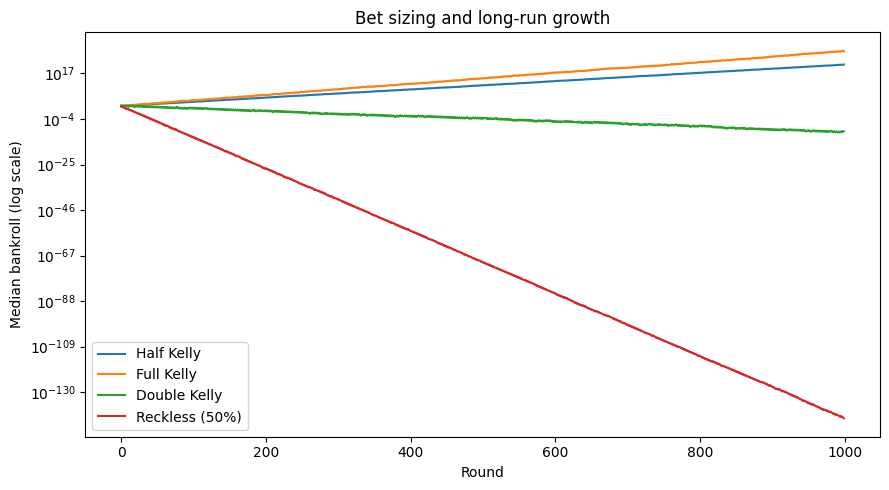

True p = 0.55: median final = 0.0, ended below start = 100.0%
True p = 0.53: median final = 0.0, ended below start = 100.0%
True p = 0.52: median final = 0.0, ended below start = 100.0%
True p = 0.51: median final = 0.0, ended below start = 100.0%


In [3]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)


P_WIN = 0.55        # true chance of winning each bet
ODDS = 1.0              # even money: win 1 for every 1 bet
N_ROUNDS = 1000      # bets per player
N_RUNS = 1000       # number of independent players simulated
START = 100.0       # starting bankroll

kelly = (ODDS * P_WIN - (1 - P_WIN)) / ODDS
print("Kelly fraction:", round(kelly, 3))

fractions = {
    "Half Kelly": 0.5 * kelly,
    "Full Kelly": kelly,
    "Double Kelly": 2 * kelly,
    "Reckless (50%)": 0.5,
}

def theory_growth(f, p=P_WIN):
    # Expected log growth per round. Highest at the Kelly fraction.
    return p * np.log(1 + ODDS * f) + (1 - p) * np.log(1 - f)

def simulate(f, p_win=P_WIN):
    wins = np.random.rand(N_RUNS, N_ROUNDS) < p_win
    growth = np.where(wins, 1 + ODDS * f, 1 - f)
    return START * np.cumprod(growth, axis=1)   # shape: runs x rounds

print(f"{'Strategy':<16}{'Median final':>14}{'% below start':>15}{'Median max drawdown':>21}{'Sim growth':>12}{'Theory':>9}")
median_paths = {}
for name, f in fractions.items():
    paths = simulate(f)
    final = paths[:, -1]
    peak = np.maximum.accumulate(paths, axis=1)
    drawdown = (1 - paths / peak).max(axis=1)
    sim_g = np.median(np.log(final / START)) / N_ROUNDS
    median_paths[name] = np.median(paths, axis=0)
    print(f"{name:<16}{np.median(final):>14.1f}{100 * np.mean(final < START):>14.1f}%{100 * np.median(drawdown):>20.1f}%{sim_g:>12.4f}{theory_growth(f):>9.4f}")

plt.figure(figsize=(9, 5))
for name, path in median_paths.items():
    plt.plot(path, label=name)
plt.yscale("log")
plt.xlabel("Round")
plt.ylabel("Median bankroll (log scale)")
plt.title("Bet sizing and long-run growth")
plt.legend()
plt.tight_layout()
plt.savefig("kelly_growth.png", dpi=150)
plt.show()

# --- Experiment 2: what if you overestimate your edge? ---
believed_f = kelly                      # you think p = 0.55 and bet 10%
for true_p in [0.55, 0.53, 0.52, 0.51]:
    final = simulate(believed_f, p_win=true_p)[:, -1]
    print(f"True p = {true_p}: median final = {np.median(final):.1f}, ended below start = {100 * np.mean(final < START):.1f}%")